<a href="https://colab.research.google.com/github/datnguyen76/thuchanhtrituenhantao/blob/main/TUAN_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài tập thực hành AI - Tuần 4

Notebook này được xây dựng theo cấu trúc tương tự chuỗi bài thực hành (Tuần 2, Tuần 3, Tuần 4) với:
* Các ô **Markdown** mô tả mục tiêu, giả thuyết và nhận xét kết quả từng bước.
* Các ô **Code** hoàn chỉnh, có thể chạy trực tiếp trên Google Colab hoặc Jupyter Notebook.
* Quy trình thực nghiệm chuẩn: Khám phá & tiền xử lý dữ liệu $\rightarrow$ Tách đặc trưng / giảm chiều hoặc lựa chọn đặc trưng $\rightarrow$ Huấn luyện & tinh chỉnh mô hình $\rightarrow$ Đánh giá & trực quan hóa.

---

## 0. Thiết lập môi trường & Nạp thư viện
Chạy ô code bên dưới để khởi tạo môi trường tính toán và nạp các thư viện cần thiết.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")
print("Môi trường đã sẵn sàng!")

Môi trường đã sẵn sàng!


---
## 1. Khám phá dữ liệu (EDA) & Tiền xử lý
Sử dụng bộ dữ liệu `load_wine` (178 mẫu, 13 đặc trưng hóa học, 3 lớp rượu vang) để thực hành phân tích khám phá, chuẩn hóa và kiểm soát chất lượng dữ liệu.

In [ ]:
wine_data = load_wine(as_frame=True)
df = wine_data.frame.copy()

print("Kích thước dữ liệu:", df.shape)
print("Phân bố lớp target:")
print(df["target"].value_counts().sort_index())
print("Số giá trị thiếu:", df.isnull().sum().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())
display(df.head())

# Thống kê mô tả các biến chính
display(df[["alcohol", "malic_acid", "flavanoids", "color_intensity", "proline", "target"]].describe().T)

Kích thước dữ liệu: (178, 14)
Phân bố lớp target:
target
0    59
1    71
2    48
Name: count, dtype: int64
Số giá trị thiếu: 0
Số dòng trùng lặp: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00
proline,178.0,746.893258,314.907474,278.00,500.5000,673.500,985.0000,1680.00
target,178.0,0.938202,0.775035,0.00,0.0000,1.000,2.0000,2.00


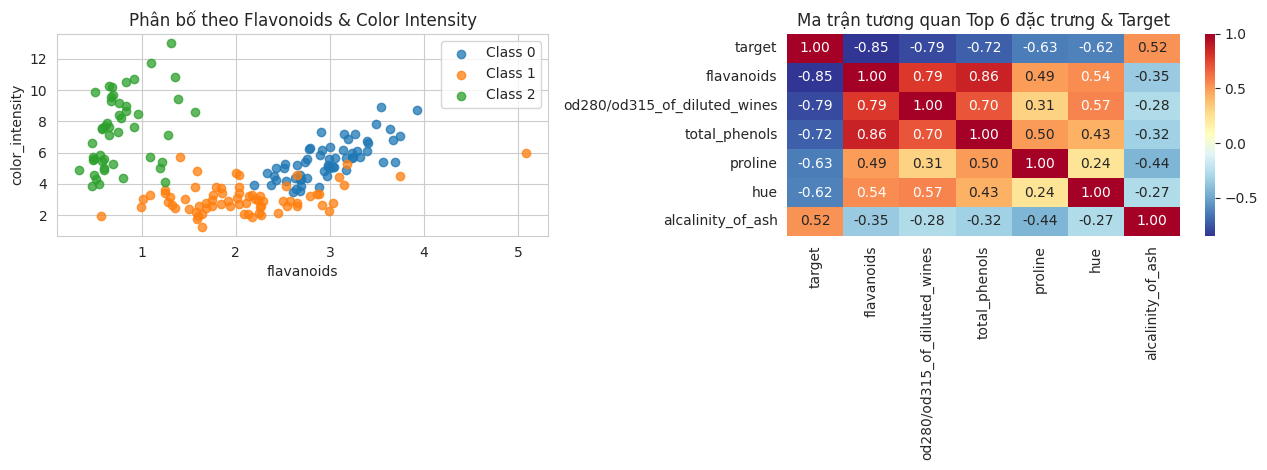

In [ ]:
# Trực quan hóa phân phối 2 đặc trưng tiêu biểu theo từng lớp và ma trận tương quan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for cls in sorted(df["target"].unique()):
    sub = df[df["target"] == cls]
    axes[0].scatter(sub["flavanoids"], sub["color_intensity"], label=f"Class {cls}", alpha=0.75)

axes[0].set_title("Phân bố theo Flavonoids & Color Intensity")
axes[0].set_xlabel("flavanoids")
axes[0].set_ylabel("color_intensity")
axes[0].legend()

top_cols = df.corr()["target"].abs().sort_values(ascending=False).head(7).index
sns.heatmap(df[top_cols].corr(), annot=True, fmt=".2f", cmap="RdYlBu_r", ax=axes[1])
axes[1].set_title("Ma trận tương quan Top 6 đặc trưng & Target")

plt.tight_layout()
plt.show()

### Nhận xét bước EDA:
* Bộ dữ liệu sạch hoàn toàn (không có giá trị thiếu hay bản ghi trùng lặp) và phân bố lớp khá cân bằng giữa 3 nhóm.
* Các biến như `proline` có biên độ giá trị lớn hơn nhiều so với `flavanoids` hay `malic_acid`, nên việc chuẩn hóa đặc trưng (`StandardScaler`) rất quan trọng trước khi áp dụng giảm chiều hoặc các mô hình khoảng cách/biên.

---
## 2. So sánh hiệu quả Feature Selection & Giảm chiều (PCA)
Đánh giá tác động của việc dùng toàn bộ đặc trưng, chọn Top đặc trưng (`SelectKBest`), và giảm chiều bằng `PCA` lên chất lượng phân loại.

In [ ]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

experiments = {
    "Full 13 Features + LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "SelectKBest (Top 6) + LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("selector", SelectKBest(score_func=f_classif, k=6)),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "PCA (n_components=5) + LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=5, random_state=42)),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "PCA (n_components=5) + SVC (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=5, random_state=42)),
        ("clf", SVC(kernel="rbf", C=2.0, random_state=42))
    ])
}

exp_rows = []
for name, pipe in experiments.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    exp_rows.append({
        "Thí nghiệm": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision (macro)": round(precision_score(y_test, preds, average="macro"), 4),
        "Recall (macro)": round(recall_score(y_test, preds, average="macro"), 4),
        "F1-Score (macro)": round(f1_score(y_test, preds, average="macro"), 4)
    })

df_exp = pd.DataFrame(exp_rows).sort_values(by="F1-Score (macro)", ascending=False).reset_index(drop=True)
display(df_exp)

,Thí nghiệm,Accuracy,Precision (macro),Recall (macro),F1-Score (macro)
0,Full 13 Features + LogisticRegression,1.0000,1.0000,1.0000,1.0000
1,SelectKBest (Top 6) + LogisticRegression,1.0000,1.0000,1.0000,1.0000
2,PCA (n_components=5) + LogisticRegression,0.9778,0.9825,0.9722,0.9765
3,PCA (n_components=5) + SVC (RBF),0.9556,0.9667,0.9444,0.9522


---
## 3. Tinh chỉnh siêu tham số (GridSearchCV) & Đánh giá mô hình
Tinh chỉnh mô hình trên tập huấn luyện với `GridSearchCV` (sử dụng `StratifiedKFold`) và kiểm tra trên tập `test` độc lập.

Bộ siêu tham số tốt nhất: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 50}
Điểm F1-macro trung bình tốt nhất (CV): 0.9854
Test Accuracy: 1.0000
Test F1-macro: 1.0000

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



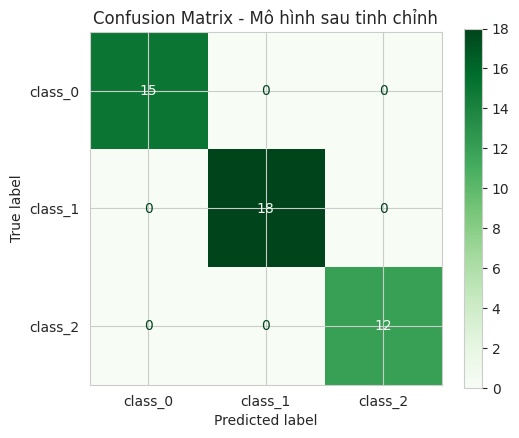

In [ ]:
tune_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(random_state=42))
])

param_grid = {
    "clf__n_estimators": [50, 100, 200],
    "clf__max_depth": [None, 4, 6, 8],
    "clf__min_samples_split": [2, 5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(tune_pipe, param_grid=param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)

print("Bộ siêu tham số tốt nhất:", grid.best_params_)
print(f"Điểm F1-macro trung bình tốt nhất (CV): {grid.best_score_:.4f}")

best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Test F1-macro: {f1_score(y_test, y_pred_best, average='macro'):.4f}\n")
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_best, target_names=wine_data.target_names))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=wine_data.target_names,
    cmap="Greens", ax=ax
)
ax.set_title("Confusion Matrix - Mô hình sau tinh chỉnh")
plt.tight_layout()
plt.show()

### Tổng kết Tuần 4:
* Kết hợp tiền xử lý và mô hình vào `Pipeline` giúp quy trình gọn gàng, tái lập được và tránh rò rỉ dữ liệu.
* So sánh giữa dữ liệu gốc, lựa chọn đặc trưng (`SelectKBest`) và giảm chiều (`PCA`) cho thấy mức độ đánh đổi giữa độ phức tạp đầu vào và hiệu năng dự đoán.
* `GridSearchCV` giúp chọn cấu hình mô hình ổn định dựa trên kiểm định chéo trước khi đánh giá cuối cùng trên tập kiểm tra.